In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from minisom import MiniSom
from sklearn.cluster import KMeans

df_scaled = pd.read_csv('../data/processed/data_scaled.csv')
X = df_scaled.values

print(X.shape)
df_scaled.head()

(400, 5)


,Signal_Strength,Latency,Required_Bandwidth,Allocated_Bandwidth,Resource_Allocation
0,0.265777,-0.181316,1.725130,2.580707,-0.525300
1,0.023942,-0.655346,-0.762862,-0.759195,0.589396
2,-0.217894,0.292713,0.468569,0.560605,0.032048
3,0.507612,-1.129376,-0.536680,-0.449446,1.704091
4,0.120676,-0.418331,-0.285368,-0.112762,1.146743


In [4]:
grid_x = 10
grid_y = 10
input_len = X.shape[1]

som = MiniSom(
    x=grid_x, 
    y=grid_y, 
    input_len=input_len, 
    sigma=1.2, 
    learning_rate=0.5, 
    random_seed=42
)

som.pca_weights_init(X)
som.train_random(data=X, num_iteration=5000, verbose=True)

 [ 5000 / 5000 ] 100% - 0:00:00 left 
 quantization error: 0.12548174134437415


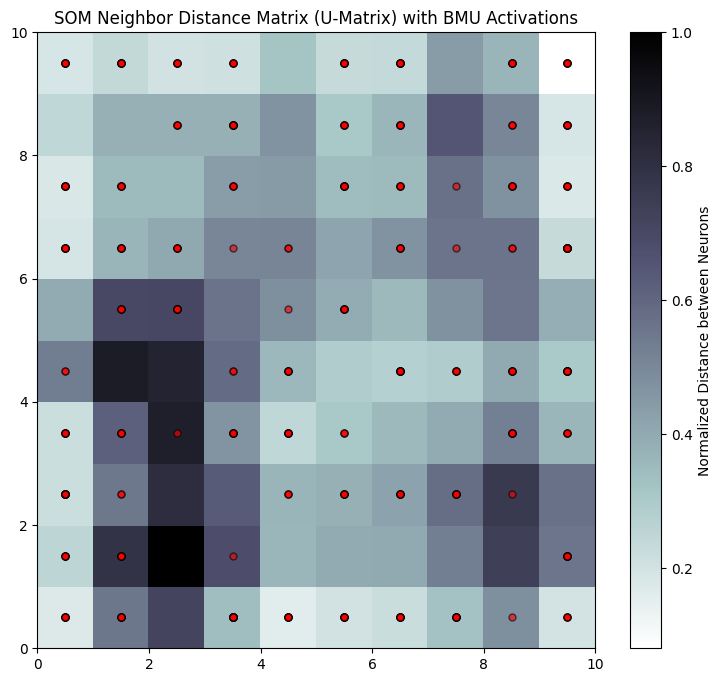

In [5]:
plt.figure(figsize=(9, 8))
u_matrix = som.distance_map().T

plt.pcolor(u_matrix, cmap='bone_r')
plt.colorbar(label='Normalized Distance between Neurons')

for idx, x_vec in enumerate(X):
    winner_neuron = som.winner(x_vec)
    plt.plot(
        winner_neuron[0] + 0.5, 
        winner_neuron[1] + 0.5, 
        marker='o', 
        markerfacecolor='red', 
        markeredgecolor='black', 
        markersize=5, 
        alpha=0.6
    )

plt.title('SOM Neighbor Distance Matrix (U-Matrix) with BMU Activations')
plt.savefig('../outputs/figures/03_som_umatrix.png', bbox_inches='tight', dpi=300)
plt.show()

In [6]:
weights = som.get_weights()
flat_weights = weights.reshape(-1, input_len)

k_clusters = 3
km_som = KMeans(n_clusters=k_clusters, n_init=100, random_state=42)
neuron_labels = km_som.fit_predict(flat_weights)
grid_labels = neuron_labels.reshape(grid_x, grid_y)

som_cluster_assignments = []
for x_vec in X:
    w = som.winner(x_vec)
    cluster_id = grid_labels[w[0], w[1]]
    som_cluster_assignments.append(cluster_id)

som_cluster_assignments = np.array(som_cluster_assignments)

pd.Series(som_cluster_assignments).value_counts().sort_index()

0    173
1    170
2     57
Name: count, dtype: int64

In [7]:
predictions_df = pd.DataFrame({'SOM_Cluster': som_cluster_assignments})
predictions_df.to_csv('../outputs/predictions/som_clusters.csv', index=False)

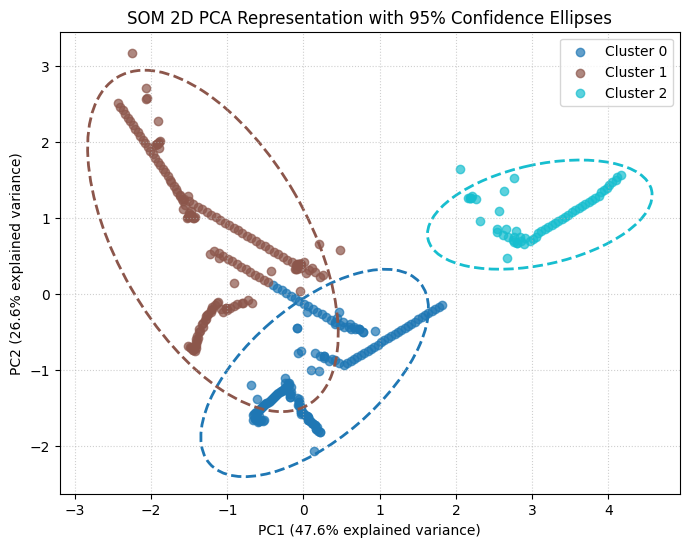

In [9]:
from sklearn.decomposition import PCA
from matplotlib.patches import Ellipse

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(8, 6))
unique_clusters = np.unique(som_cluster_assignments)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_clusters)))

for idx, c in enumerate(unique_clusters):
    pts = X_pca[som_cluster_assignments == c]
    ax.scatter(pts[:, 0], pts[:, 1], label=f"Cluster {c}", color=colors[idx], alpha=0.7)
    
    if len(pts) > 2:
        cov = np.cov(pts[:, 0], pts[:, 1])
        vals, vecs = np.linalg.eigh(cov)
        order = vals.argsort()[::-1]
        vals, vecs = vals[order], vecs[:, order]
        
        theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
        chi2_val = 5.991
        width = 2 * np.sqrt(vals[0] * chi2_val)
        height = 2 * np.sqrt(vals[1] * chi2_val)
        center = np.mean(pts, axis=0)
        
        ellipse = Ellipse(xy=center, width=width, height=height, angle=theta, edgecolor=colors[idx], fc='none', lw=2, linestyle='--')
        ax.add_patch(ellipse)

ax.set_title("SOM 2D PCA Representation with 95% Confidence Ellipses")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% explained variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% explained variance)")
ax.legend()
ax.grid(True, linestyle=":", alpha=0.6)

plt.savefig("../outputs/figures/03_som_pca_ellipses.png", bbox_inches="tight", dpi=300)
plt.show()

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import pandas as pd
import numpy as np

latent_dim = 2
k_clusters = 3
data_dim = X.shape[1]

net_G = nn.Sequential(
    nn.Linear(latent_dim + k_clusters, 64),
    nn.LeakyReLU(0.2),
    nn.Linear(64, 64),
    nn.LeakyReLU(0.2),
    nn.Linear(64, data_dim)
)

net_D = nn.Sequential(
    nn.Linear(data_dim, 64),
    nn.LeakyReLU(0.2),
    nn.Linear(64, 32),
    nn.LeakyReLU(0.2),
    nn.Linear(32, 1)
)

net_E = nn.Sequential(
    nn.Linear(data_dim, 64),
    nn.LeakyReLU(0.2),
    nn.Linear(64, 64),
    nn.LeakyReLU(0.2),
    nn.Linear(64, latent_dim + k_clusters)
)

In [15]:
torch.manual_seed(42)
np.random.seed(42)

tensor_X = torch.tensor(X, dtype=torch.float32)
dataset = TensorDataset(tensor_X)
loader = DataLoader(dataset, batch_size=32, shuffle=True)

opt_D = optim.Adam(net_D.parameters(), lr=0.0005, betas=(0.5, 0.999))
opt_GE = optim.Adam(list(net_G.parameters()) + list(net_E.parameters()), lr=0.0005, betas=(0.5, 0.999))

loss_cluster = nn.CrossEntropyLoss()
loss_noise = nn.MSELoss()

epochs = 150

for epoch in range(1, epochs + 1):
    for batch in loader:
        real_x = batch[0]
        n_samples = real_x.size(0)

        zn = torch.randn(n_samples, latent_dim)
        labels = torch.randint(0, k_clusters, (n_samples,))
        zc = torch.zeros(n_samples, k_clusters).scatter_(1, labels.unsqueeze(1), 1.0)

        opt_D.zero_grad()
        fake_x = net_G(torch.cat([zn, zc], dim=1)).detach()
        loss_d = -torch.mean(net_D(real_x)) + torch.mean(net_D(fake_x))
        loss_d.backward()
        opt_D.step()

        for param in net_D.parameters():
            param.data.clamp_(-0.01, 0.01)

        opt_GE.zero_grad()
        fake_gen = net_G(torch.cat([zn, zc], dim=1))
        loss_adv = -torch.mean(net_D(fake_gen))

        e_out = net_E(fake_gen)
        zn_hat, zc_logits = torch.split(e_out, [latent_dim, k_clusters], dim=1)

        loss_cycle = loss_cluster(zc_logits, labels) + loss_noise(zn_hat, zn)
        loss_total = loss_adv + 10.0 * loss_cycle
        loss_total.backward()
        opt_GE.step()

print("ClusterGAN training completed.")

ClusterGAN training completed.


In [16]:
net_E.eval()

with torch.no_grad():
    e_out = net_E(tensor_X)
    _, zc_logits = torch.split(e_out, [latent_dim, k_clusters], dim=1)
    clustergan_labels = torch.argmax(zc_logits, dim=1).numpy()

print(pd.Series(clustergan_labels).value_counts().sort_index())

df_preds = pd.DataFrame({"ClusterGAN_Cluster": clustergan_labels})
df_preds.to_csv("../outputs/predictions/clustergan_clusters.csv", index=False)

0    250
1     78
2     72
Name: count, dtype: int64


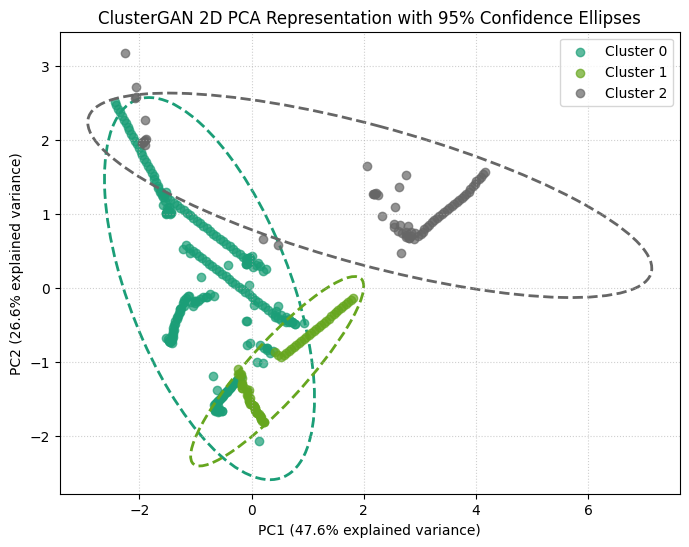

In [17]:
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

fig, ax = plt.subplots(figsize=(8, 6))
unique_groups = np.unique(clustergan_labels)
colors = plt.cm.Dark2(np.linspace(0, 1, len(unique_groups)))

for idx, g in enumerate(unique_groups):
    pts = X_pca[clustergan_labels == g]
    ax.scatter(pts[:, 0], pts[:, 1], label=f"Cluster {g}", color=colors[idx], alpha=0.7)

    if len(pts) > 2:
        cov = np.cov(pts[:, 0], pts[:, 1])
        vals, vecs = np.linalg.eigh(cov)
        order = vals.argsort()[::-1]
        vals, vecs = vals[order], vecs[:, order]

        theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
        w = 2 * np.sqrt(vals[0] * 5.991)
        h = 2 * np.sqrt(vals[1] * 5.991)
        center = np.mean(pts, axis=0)

        ellipse = Ellipse(xy=center, width=w, height=h, angle=theta, edgecolor=colors[idx], fc='none', lw=2, linestyle='--')
        ax.add_patch(ellipse)

ax.set_title("ClusterGAN 2D PCA Representation with 95% Confidence Ellipses")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% explained variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% explained variance)")
ax.legend()
ax.grid(True, linestyle=":", alpha=0.6)

plt.savefig("../outputs/figures/03_clustergan_pca_ellipses.png", bbox_inches="tight", dpi=300)
plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.cluster import KMeans
import pandas as pd
import numpy as np

latent_dim = 3
data_dim = X.shape[1]

encoder = nn.Sequential(
    nn.Linear(data_dim, 32),
    nn.ReLU(),
    nn.Linear(32, latent_dim)
)

decoder = nn.Sequential(
    nn.Linear(latent_dim, 32),
    nn.ReLU(),
    nn.Linear(32, data_dim)
)

autoencoder = nn.Sequential(encoder, decoder)

In [19]:
torch.manual_seed(42)
np.random.seed(42)

tensor_X = torch.tensor(X, dtype=torch.float32)
loader = DataLoader(TensorDataset(tensor_X), batch_size=32, shuffle=True)

optimizer = optim.Adam(autoencoder.parameters(), lr=0.005)
criterion = nn.MSELoss()

epochs = 150
for epoch in range(1, epochs + 1):
    for batch in loader:
        real_x = batch[0]
        optimizer.zero_grad()
        reconstructed_x = autoencoder(real_x)
        loss = criterion(reconstructed_x, real_x)
        loss.backward()
        optimizer.step()

print("Autoencoder training completed.")

Autoencoder training completed.


In [20]:
encoder.eval()
with torch.no_grad():
    latent_representation = encoder(tensor_X).numpy()

km_ae = KMeans(n_clusters=3, n_init=50, random_state=42)
ae_clusters = km_ae.fit_predict(latent_representation)

print(pd.Series(ae_clusters).value_counts().sort_index())

df_ae = pd.DataFrame({'Autoencoder_Cluster': ae_clusters})
df_ae.to_csv('../outputs/predictions/autoencoder_clusters.csv', index=False)

0    219
1     70
2    111
Name: count, dtype: int64


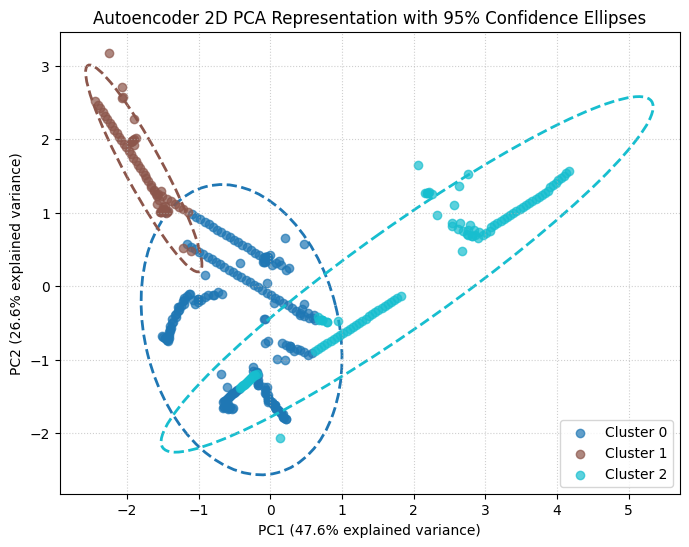

In [21]:
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

fig, ax = plt.subplots(figsize=(8, 6))
unique_groups = np.unique(ae_clusters)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_groups)))

for idx, g in enumerate(unique_groups):
    pts = X_pca[ae_clusters == g]
    ax.scatter(pts[:, 0], pts[:, 1], label=f"Cluster {g}", color=colors[idx], alpha=0.7)

    if len(pts) > 2:
        cov = np.cov(pts[:, 0], pts[:, 1])
        vals, vecs = np.linalg.eigh(cov)
        order = vals.argsort()[::-1]
        vals, vecs = vals[order], vecs[:, order]

        theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
        w = 2 * np.sqrt(vals[0] * 5.991)
        h = 2 * np.sqrt(vals[1] * 5.991)
        center = np.mean(pts, axis=0)

        ellipse = Ellipse(xy=center, width=w, height=h, angle=theta, edgecolor=colors[idx], fc='none', lw=2, linestyle='--')
        ax.add_patch(ellipse)

ax.set_title("Autoencoder 2D PCA Representation with 95% Confidence Ellipses")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% explained variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% explained variance)")
ax.legend()
ax.grid(True, linestyle=":", alpha=0.6)

plt.savefig("../outputs/figures/03_autoencoder_pca_ellipses.png", bbox_inches="tight", dpi=300)
plt.show()